# CCF region aggregation and spatial warning flags

This tutorial demonstrates how to aggregate voxel-wise predictions per CCF region and to generate spatial warning flags for the 3D spatial predictions generated in the SpatialSmoothing notebook.

As an example, we will aggregate the data and recreate the flags from the paper up to a user-specified level here (default = L2).

In this notebook, we will:
1. Aggregate predictions per CCF region.
2. Derive DBSCAN metrics to describe the spatial pattern of spatial predictions (Shape)
3. Calculate the number of high confidence ST cells to quantify the "Signal" from which spatial predictions were generated
4. Flag predictions if chosen thresholds are exceeded.

Requirements:
To run the notebook you will need:
1. HypoMap3D's code base and environment. For this, follow the instructions at the root of the Git repo.
2. HypoMap3D cell-wise and voxel-wise spatial datasets. Download them and place it into DATADIR/9_objects/spatial/hypomap3d_spatial_voxel_level.zarr and DATADIR/9_objects/spatial/hypomap3d_spatial_cell_level.h5ad, respectively.

Of course, the above paths can be modified but then they have to be changed accordingly below as well.

If you wish to use our own data, file paths must be changed accordingly as well.

### Imports

In [1]:
import warnings
import json
from pathlib import Path
import concurrent

import pandas as pd
import scanpy as sc
import numpy as np
import zarr

from dotenv import dotenv_values
from matplotlib import pyplot as plt
from skimage.filters import threshold_otsu
from sklearn.cluster import DBSCAN
from scipy import sparse
from matplotlib import pyplot as plt
import seaborn as sns
from matplotlib.patches import Patch
import matplotlib.gridspec as gridspec

warnings.simplefilter(action='ignore', category=FutureWarning)
sc.set_figure_params(frameon=False, dpi=120, figsize=(5, 5))

### File paths

Change them if you want to use your own data.

In [ ]:
CONFIG = dotenv_values("config.env") # file at the root of your cloned repo
DATADIR = Path(CONFIG['DATADIR']) # root of your DATADIR

SPATIALDIR = DATADIR / "9_objects" / "spatial"
ZARR_FP = SPATIALDIR / "hypomap3d_spatial_voxel_level.zarr"
ST_ADATA_FP = SPATIALDIR / "hypomap3d_spatial_cell_level.h5ad"

OUTDIR = DATADIR / "tutorials"
OUTDIR.mkdir(exist_ok=True, parents=True)

## Data loading

In [3]:
# Load voxel grid Zarr store
voxel_store = zarr.open(ZARR_FP)
#voxel_store.tree()

### Notebook settings

As the code can run quite a while to get the DBSCAN metrics for the full object later, we will only analyze for clustering resolutions L1-2 here.

If you wish to analyze all levels, set MAX_LEVEL_TO_ANALYZE to 5.

In [ ]:
MAX_LEVEL_TO_ANALYZE = 2

## Let's aggregate predictions per CCF region

Here, we sum up all voxel-wise relative masses per CCF region.

In [ ]:
def get_region_distribution(voxel_store, level: int) -> pd.DataFrame:
    """
    For a given level i, creates a DataFrame of shape (n_labels, n_regions)
    where each entry is the sum of rel_mass for that label within that brain region,
    excluding NaN voxels.

    Parameters
    ----------
    voxel_store : zarr Group
        The zarr store containing the arrays
    level : int
        The level i to use (e.g. 1 for L1, 2 for L2, etc.)

    Returns
    -------
    pd.DataFrame of shape (n_labels, n_regions)
        index: label descr
        columns: brain region ids
    """

    # Load region labels and flatten
    region_labels_flat = voxel_store["region"]["region_labels"][:].reshape(-1)  # (nx*ny*nz,)
    unique_regions = np.unique(region_labels_flat)
    n_regions = len(unique_regions)

    # Map region ids to column indices
    region_to_idx = {r: i for i, r in enumerate(unique_regions)}
    region_idx = np.array([region_to_idx[r] for r in region_labels_flat])  # (n_voxels,)

    # Get metadata
    label_descr = voxel_store[f"L{level}"]["descr"][:]
    n_labels = len(label_descr)

    # Preallocate result
    result = np.zeros((n_labels, n_regions), dtype=np.float32)

    # Iterate over labels one at a time to keep memory low
    for i in range(n_labels):
        # Load single label slice and flatten
        label_mass = voxel_store[f"L{level}"]["rel_mass"][i].reshape(-1)  # (n_voxels,)

        # Mask out NaN voxels
        valid_mask = ~np.isnan(label_mass)

        # Only accumulate non-NaN values
        np.add.at(result[i], region_idx[valid_mask], label_mass[valid_mask])

    # Prep output
    df = pd.DataFrame(result, index=label_descr, columns=unique_regions)
    df.drop(columns=0, inplace=True) # remove outside-of-brain indicator region

    return df


In [27]:
dfs = []
for i in range(1,MAX_LEVEL_TO_ANALYZE+1):
    dfs.append(get_region_distribution(voxel_store, level = i))
rm_complete = pd.concat(dfs, axis=0)

The results are aggregated relative masses per Allen Brain Cell (ABC) region ID, with the "root" region filtered out by default.

Some of those IDs are from non-hypothlamic regions which are only covered by a few voxels.

Hence, we will filter the table to brain regions which were covered to a meaningful extent in HypoMap3D's bounding box. The corresponding regions have their IDs and acronyms available in the zarr store.

After filtering for meaningful regions and mapping their acronyms, we will renormalize the data, such that the relative masses sum up to 1 over all brain regions.

In [28]:
rm_complete.head()

,1,6,12,15,23,27,30,38,54,56,...,606826655,606826659,607344830,607344834,607344838,607344846,607344850,607344854,607344858,607344862
Gb1-2 GABA,0.001156,0.011916,0.000149,0.000666,0.008469,0.000025,0.001316,0.001100,0.000139,0.060656,...,0.000014,0.000133,0.000041,0.000378,0.000033,0.000051,0.000041,4.264802e-07,0.000042,0.000097
Gl1-1 Glut,0.001087,0.010417,0.001106,0.006570,0.005710,0.000036,0.000740,0.007335,0.001130,0.003005,...,0.002007,0.002867,0.000128,0.001191,0.000073,0.000117,0.000074,6.176414e-06,0.000169,0.000396
NN1-1 OPC-Oligo,0.000722,0.061648,0.000806,0.002875,0.004488,0.000047,0.000344,0.001268,0.000906,0.009465,...,0.000258,0.000630,0.000261,0.001194,0.000188,0.000197,0.000136,1.249357e-05,0.000150,0.000332
NN1-2 Immune,0.000739,0.018307,0.000455,0.002621,0.007492,0.000031,0.001054,0.005476,0.000693,0.015901,...,0.000460,0.000589,0.000225,0.001545,0.000200,0.000466,0.000134,1.442631e-06,0.000215,0.000225
NN1-3 Vascular,0.004209,0.013169,0.000790,0.004443,0.010185,0.000040,0.000538,0.003712,0.000741,0.013107,...,0.001046,0.003313,0.000154,0.001816,0.000258,0.000363,0.000102,3.659279e-06,0.000133,0.000438


In [29]:
# 1. Build the mapping
region_ids = voxel_store["region"]["ids"][:]
region_acronyms = voxel_store["region"]["acronyms"][:]
acro_mapper = dict(zip(region_ids, region_acronyms))

# 2. Filter columns
rm_complete = rm_complete.loc[:, rm_complete.columns.isin(region_ids)]

# 3. Rename columns
rm_complete = rm_complete.rename(columns=acro_mapper)

# 4. Normalize rows
row_sums = rm_complete.sum(axis=1)
rm_complete = rm_complete.div(row_sums, axis=0)

In [30]:
rm_complete.head()

,TMv,int,IF,PT,AAA,PVa,PVH,mfb,ACB,MT,...,IntG,VMPO,PeF,HATA,MMl,MMm,MMp,MMd,IPR,IPRL
Gb1-2 GABA,0.001158,0.011932,0.000149,0.000667,0.008481,0.001318,0.001102,0.000140,0.060741,0.000325,...,0.000151,0.000884,0.002197,0.001060,0.000125,0.000066,0.000014,0.000133,0.000379,0.000097
Gl1-1 Glut,0.001091,0.010453,0.001110,0.006593,0.005730,0.000742,0.007361,0.001134,0.003016,0.000441,...,0.000338,0.000723,0.002503,0.002206,0.009730,0.007730,0.002014,0.002878,0.001195,0.000397
NN1-1 OPC-Oligo,0.000724,0.061816,0.000808,0.002883,0.004501,0.000345,0.001271,0.000908,0.009491,0.000881,...,0.000347,0.000633,0.004861,0.000510,0.001915,0.001060,0.000258,0.000632,0.001197,0.000333
NN1-2 Immune,0.000741,0.018360,0.000457,0.002629,0.007514,0.001057,0.005492,0.000695,0.015947,0.000742,...,0.000209,0.000871,0.004023,0.000959,0.001137,0.000758,0.000461,0.000591,0.001549,0.000225
NN1-3 Vascular,0.004224,0.013215,0.000793,0.004458,0.010220,0.000540,0.003725,0.000744,0.013152,0.000923,...,0.000431,0.000429,0.002435,0.001825,0.004143,0.002152,0.001050,0.003325,0.001822,0.000440


What subclasses have their highest relative mass in the ARH?

In [31]:
rm_complete.loc[:, "ARH"].sort_values(ascending=False).head()

Gl2-28 ARH-PVp Tbx3.Kiss1       0.383984
Gb2-63 TU-ARH Otp.Six6.Npy2r    0.354879
Gl2-32 ARH-PVp Tbx3.Isl1        0.252659
Gb2-60 ARH-PVp Tbx3             0.222384
Gb2-67 SBPV-PVa Six6.Satb2      0.148098
Name: ARH, dtype: float32

Let's save!

In [ ]:
rm_complete.to_csv(OUTDIR / "region_wise_relative_masses.csv")

## Let's get metrics describing the 3D pattern of spatial predictions

For this matter, voxel-wise probabilities are binarized using the Otsu algorithm as to distinguish foreground vs background voxels, where foreground voxels indicate the regions in which a cell type is likely to be located.

Afterwards, the DBSCAN clustering algorithm is applied to the x, y, z coordinates of the foreground voxels as to estimate in how many hot spots a cluster is located, how voluminous those hot spots are and how much spatial scatter is in the predictions as evidenced by high counts of DBSCAN clusters as well as outlier points. 

By using an epsilon of 0.1, new spatial DBSCAN clusters form if they are at least 100 micrometer away from other hot spots. 

In [ ]:
def get_DBSCAN_clusters(voxel_store, coords, lvl: int, eps: float, min_samples: int) -> pd.DataFrame:
    """
    Run DBSCAN clustering on voxel probabilities for each celltype at a given hierarchy level.

    Args:
        voxel_store:  zarr/h5 store containing relative mass arrays of shape (n_celltypes, nx, ny, nz)
        coords:       voxel coordinates of shape (nx*ny*nz, 3)
        lvl:          hierarchy level to process
        eps:          DBSCAN epsilon (neighborhood radius)
        min_samples:  DBSCAN minimum samples per cluster

    Returns:
        pd.DataFrame with columns: cluster_name, otsu_thr, dbscan_label,
                                   num_vox, percent_vox, center_coords, rel_mass
    """
    # init lists to collect data for a long df
    cluster_list = []
    thr_list = []
    label_list = []
    label_count_list = []
    label_count_relative_list = []
    center_coords_list = []
    rm_list = []

    group = voxel_store[f"L{lvl}"]
    celltypes = group["ids"][:]

    for i, celltype in enumerate(celltypes):

        probs = group["prob"][i, :, :, :].reshape(-1)
        probs = np.nan_to_num(probs, nan=0.0)
        relmass = group[f"rel_mass"][i, :, :, :].reshape(-1)
        relmass = np.nan_to_num(relmass, nan=0.0)

        try:
            thr = threshold_otsu(probs)
            mask = probs > thr

            dat = pd.DataFrame(data=coords[mask, :], columns=["x", "y", "z"])
            dat["rel_mass"] = relmass[mask]
            total_vox = len(dat)

            db = DBSCAN(eps=eps, min_samples=min_samples).fit(dat[["x", "y", "z"]].values)
            labels = list(db.labels_)
            dat["labels"] = labels

            for label in dat["labels"].unique():
                label_mask = dat["labels"] == label
                count = labels.count(label)
                center = dat[label_mask][["x", "y", "z"]].mean().values

                cluster_list.append(celltype)
                thr_list.append(thr)
                label_list.append(label)
                label_count_list.append(count)
                label_count_relative_list.append(count / total_vox)
                center_coords_list.append(center)
                rm_list.append(dat[label_mask]["rel_mass"].sum())

        except Exception as e:
            print(f"Skipping celltype '{celltype}' at level {lvl}: {e}")
            cluster_list.append(celltype)
            thr_list.append(np.nan)
            label_list.append(np.nan)
            label_count_list.append(np.nan)
            label_count_relative_list.append(np.nan)
            center_coords_list.append([np.nan, np.nan, np.nan])
            rm_list.append(np.nan)

    df = pd.DataFrame.from_dict({
        "cluster": cluster_list,
        "otsu_thr": thr_list,
        "dbscan_label": label_list,
        "num_vox": label_count_list,
        "percent_vox": label_count_relative_list,
        "center_coords": center_coords_list,
        "rel_mass": rm_list
    })

    return df

In [33]:
EPS = 0.1
MIN_SAMPLES = 3

First, let us precompute a coordinate grid which we will use to additionally derive center CCF [mm] coordinates for the hotspots.

In [34]:
x_min, y_min, z_min = np.round(
    voxel_store["bbox"]["ccf_mm"]["min"][:], 3
)
x_max, y_max, z_max = np.round(
    voxel_store["bbox"]["ccf_mm"]["max"][:], 3
)

print(f"x: {x_min:.3f} <-> {x_max:.3f}")
print(f"y: {y_min:.3f} <-> {y_max:.3f}")
print(f"z: {z_min:.3f} <-> {z_max:.3f}")

step = 0.025 # 25 um steps

xx = np.round(np.arange(x_min, x_max + step, step), 3)
yy = np.round(np.arange(y_min, y_max + step, step), 3)
zz = np.round(np.arange(z_min, z_max + step, step), 3)

print(len(xx), len(yy), len(zz))

X, Y, Z = np.meshgrid(xx, yy, zz, indexing="ij")
grid = np.stack([X, Y, Z], axis=-1)
coords = grid.reshape(-1, 3)
coords

x: 4.375 <-> 8.550
y: 3.950 <-> 7.525
z: 3.050 <-> 5.700
168 144 107


array([[4.375, 3.95 , 3.05 ],
       [4.375, 3.95 , 3.075],
       [4.375, 3.95 , 3.1  ],
       ...,
       [8.55 , 7.525, 5.65 ],
       [8.55 , 7.525, 5.675],
       [8.55 , 7.525, 5.7  ]], shape=(2588544, 3))

In [ ]:
dfs=[] # this will run for hours
for lvl in range(1,MAX_LEVEL_TO_ANALYZE + 1):
    df = get_DBSCAN_clusters(voxel_store, coords, lvl = lvl, eps = EPS, min_samples = MIN_SAMPLES)
    dfs.append(df)
db_metrics = pd.concat(dfs, axis=0)

In [ ]:
db_metrics.head(3)

,cluster,otsu_thr,dbscan_label,num_vox,percent_vox,center_coords,rel_mass
0,Gb1-2,0.36083,0,655478,0.960281,"[5.1485277156525076, 5.528380815222316, 4.1422...",0.618054
1,Gb1-2,0.36083,-1,14,0.000021,"[6.7, 5.789285714285714, 4.269642857142856]",0.000008
2,Gb1-2,0.36083,1,28,0.000041,"[5.336607142857141, 6.912500000000001, 5.06785...",0.000016


In [80]:
db_metrics.to_csv(OUTDIR / "dbscan_metrics.csv", index=False)

## Let's get signal metrics

To estimate how much "signal" there is the ST dataset that was smoothed we count the number of high confidence cells per cluster.

Here, "high confidence" is defined by a membership probability > 0.5.

In [ ]:
HI_CONF_THR = 0.5 # high confidence threshold

In [ ]:
adata = sc.read_h5ad(ST_ADATA_FP, backed="r")

To obtain the number of high confidence cells we use the previously stored pathmat which containsthe paths through our clustering tree from L1 to L5 as well as adata.obsm["P_L5"] which stores path probablities for all L5 clusters, shape (n_cells, n leaf (ie L5) clusters).

Hence, in the loop below, path probabilities are summed up for all parent clusters of L5 clusters when assessing L4 clusters for instance. 

Afterwards, it is checked whether the resulting probabilities exceed the above high confidence threshold.

In [ ]:
pathmat = pd.DataFrame(data=adata.uns["pathmat"], columns=[f"L{i}" for i in range(1,6)])

In [ ]:
pathmat.head()

,L1,L2,L3,L4,L5
0,Gb1-2,Gb2-39,Gb3-124,Gb4-319,Gb5-428
1,Gb1-2,Gb2-39,Gb3-124,Gb4-320,Gb5-429
2,Gb1-2,Gb2-39,Gb3-124,Gb4-321,Gb5-430
3,Gb1-2,Gb2-39,Gb3-124,Gb4-321,Gb5-431
4,Gb1-2,Gb2-39,Gb3-124,Gb4-322,Gb5-432


In [ ]:
# Ensure P_path is CSC format for efficient column slicing
P_path = adata.obsm["P_L5"]
if sparse.issparse(P_path):
    P_path = P_path.tocsc()  # CSC is efficient for column indexing
else:
    P_path = sparse.csc_matrix(P_path)

rows = []

for level in [f"L{i}" for i in range(1,MAX_LEVEL_TO_ANALYZE+1)]:
    clusters = pathmat[level].unique()

    for cluster in clusters:
        # Find which path indices (columns) pass through this cluster
        path_indices = pathmat.index[pathmat[level] == cluster].tolist()

        # Sum probabilities across relevant columns — stays sparse
        cluster_probs = P_path[:, path_indices].sum(axis=1)  # shape: (n_cells, 1), np.matrix

        # Count cells exceeding threshold — np.matrix.A1 flattens to 1D array
        n_hi_conf = (cluster_probs.A1 > HI_CONF_THR).sum()

        rows.append({"level": level, "cluster": cluster, f"n_cells_presmooth_p_gt_{HI_CONF_THR}": n_hi_conf})

results_df = (
    pd.DataFrame(rows)
    .sort_values(["level", "cluster"])
    .reset_index(drop=True)
)

In [ ]:
results_df.head()

,level,cluster,n_cells_presmooth_p_gt_0.5
0,L1,Gb1-2,433607
1,L1,Gl1-1,256902
2,L1,NN1-1,231723
3,L1,NN1-2,21381
4,L1,NN1-3,129944


In [83]:
results_df.to_csv(OUTDIR / "high_confidence_cells.csv", index=False)

## Let's assign warning flags to all clusters

The above data is wrangled a bit to extract some key features we are interested in.

For "Signal"/"No Cells" flags, we use the number of high confidence cells.

For "Shape" flags, we consider 
- the number of DBSCAN clusters 
- the percentage of hotspot voxels that are not in the top 2 biggest hotspots 
- the volume of the biggest DBSCAN cluster

These shape metrics thus quantify spatial patterns that may be unspecific to brain regions or may be very noisy/scattery.

To flag spatial predictions for our clusters, we use thresholds for signal and shape metrics as derived from extensive EDA, c.f. below.

### Data wrangling

In [ ]:
def restrict_dbscanmetrics_to_top_k(df: pd.DataFrame, metric: str, k: int = 3) -> pd.DataFrame:
    """
    function to restrict the desired metric of the dbscan metrics to the top k dbscan labels.
    all other labels will be set to the "rest" label for which the metric will be summed.

    returns df
    """

    cluster_names_list = []
    otsu_thr_list = []
    label_list = []
    num_vox_list = []
    metric_list = []
    rank_list = []

    for cluster in df.cluster.unique():

        cluster_data = df.loc[df.cluster == cluster, :].sort_values(by=metric, ascending = False)

        # keep the top k
        top_k = cluster_data.iloc[:k, :]
        # create a column for the rank
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            top_k["size_rank"] = [str(i) for i in range(len(top_k))]

        cluster_names_list.extend(top_k.cluster.to_list())
        otsu_thr_list.extend(top_k.otsu_thr.to_list())
        label_list.extend(top_k.dbscan_label.to_list())
        num_vox_list.extend(top_k.num_vox.to_list())
        metric_list.extend(top_k[metric].to_list())
        rank_list.extend(top_k.size_rank.to_list())

        # calculate rests
        rest = cluster_data.iloc[k:, :]
        if len(rest) > 0:
            cluster_names_list.append(cluster)
            otsu_thr_list.append(rest.otsu_thr.iloc[0])
            label_list.append("rest")
            num_vox_list.append(rest.num_vox.sum())
            metric_list.append(rest[metric].sum())
            rank_list.append("rest")

    out = pd.DataFrame.from_dict({

        "cluster": cluster_names_list,
        "otsu_thr": otsu_thr_list,
        "dbscan_label": label_list,
        "num_vox": num_vox_list,
        metric: metric_list,
        "size_rank": rank_list
    })

    return out


def wrangle_dbscan(df):

    out=df.copy()

    # num clusters
    nums = out.groupby("cluster")["dbscan_label"].count().rename("num_postsmooth_dbscan_clusters")

    # top 2 and "rest" clusters
    top_k = obtain_wide_top_k_df(out)


    return pd.concat([nums, top_k], axis=1)


def obtain_wide_top_k_df(df):

    top_k = restrict_dbscanmetrics_to_top_k(df, metric="percent_vox", k = 2)

    clusters = top_k.cluster.unique()

    # Use ThreadPoolExecutor to process clusters concurrently
    all_metrics = []
    with concurrent.futures.ThreadPoolExecutor() as executor:
        # Start the load opeartions by submitting tasks to the thread pool and collect the results
        future_to_cluster = {
            executor.submit(get_wide_top_k_for_cluster, top_k, cluster): cluster
            for cluster in clusters
        }

        # Retrieve the results as they complete
        for future in concurrent.futures.as_completed(future_to_cluster):
            cluster_metrics = future.result()
            all_metrics.append(cluster_metrics)

    # Create a DataFrame from the list of dictionaries
    df = pd.DataFrame(all_metrics)

    # extract values from lists
    for col in ["num_vox_biggest_dbscan_cluster",
                "percent_vox_biggest_dbscan_cluster",
                "num_vox_second_biggest_dbscan_cluster",
                "percent_vox_second_biggest_dbscan_cluster",
                "num_vox_rest_dbscan_cluster",
                "percent_vox_rest_dbscan_cluster"]:

        df[col] = df[col].apply(lambda x: x[0] if len(x) > 0 else np.nan)

    return df.set_index("cluster")


def get_wide_top_k_for_cluster(df, cluster):
    data = df.loc[df.cluster == cluster,:]

    res = {
        "cluster": cluster,
        "num_vox_biggest_dbscan_cluster": data.loc[data.size_rank == "0", "num_vox"].values,
        "percent_vox_biggest_dbscan_cluster": data.loc[data.size_rank == "0", "percent_vox"].values,
        "num_vox_second_biggest_dbscan_cluster": data.loc[data.size_rank == "1", "num_vox"].values,
        "percent_vox_second_biggest_dbscan_cluster": data.loc[data.size_rank == "1", "percent_vox"].values,
        "num_vox_rest_dbscan_cluster": data.loc[data.size_rank == "rest", "num_vox"].values,
        "percent_vox_rest_dbscan_cluster": data.loc[data.size_rank == "rest", "percent_vox"].values,

    }
    return res


In [ ]:
# for all clusters and DBSCAN metrics, extract top 2 DBSCAN clusters, label the rest of them as "rest"
shape_df = wrangle_dbscan(db_metrics)
signal_df = results_df.set_index("cluster")
joined = pd.concat([signal_df, shape_df], axis=1).reset_index().rename(columns = {
    "index": "cluster",
    "level": "clustering"
})

joined = joined.fillna(0)
otsu_mapper = db_metrics.loc[:, ["cluster", "otsu_thr"]].drop_duplicates().set_index("cluster").to_dict()["otsu_thr"]
joined["otsu_thr"] = joined.cluster.map(otsu_mapper)

joined.head(2)

,cluster,clustering,n_cells_presmooth_p_gt_0.5,num_postsmooth_dbscan_clusters,num_vox_biggest_dbscan_cluster,percent_vox_biggest_dbscan_cluster,num_vox_second_biggest_dbscan_cluster,percent_vox_second_biggest_dbscan_cluster,num_vox_rest_dbscan_cluster,percent_vox_rest_dbscan_cluster,otsu_thr
0,Gb1-2,L1,433607,23,655478,0.960281,13981.0,0.020482,13131.0,0.019237,0.36083
1,Gl1-1,L1,256902,32,809905,0.994593,2793.0,0.003430,1610.0,0.001977,0.21526


### Let's set our thresholds

Thresholds were adapted to the specific levels, becoming more stringent with higher clustering granularity as predictions for cell types at coarser clustering resolutions are expected to include ST cells from multiple brain regions that could possibly be far away from one another.

In [ ]:
MIN_NUM_CELLS_WARNING = 10

NUM_VOX_BIGGEST_MAX = 60_000 # starting at L3

DBSCAN_CLUSTER_MAX_L2 = 200
DBSCAN_CLUSTER_MAX_L3 = 100
DBSCAN_CLUSTER_MAX_L4_L5 = 50

DBSCAN_REST_VOX_MAX_L2_L3 = 0.4
DBSCAN_REST_VOX_MAX_L4_L5 = 0.3

### Let's add our flags

Importantly, neuronal and non-neuronal cells are treated differently: Non-neuronal cells will not receive shape warnings as their shape in 3D is expected to be all over the place (consider astrocytes). 

In [ ]:
# Signal warnings are identical for all levels and cell types

joined["signal_warning"] = joined["n_cells_presmooth_p_gt_0.5"] < MIN_NUM_CELLS_WARNING

joined["no_cells_warning"] = joined["n_cells_presmooth_p_gt_0.5"] == 0

In [ ]:
# shape: only neurons
joined["shape_warning"] = False # init shape
neuron_mask = ~joined.cluster.str.contains("NN")

In [ ]:
level = "L2"

joined.loc[
    (neuron_mask) &
    (joined.clustering == level) &
    ((joined.num_postsmooth_dbscan_clusters > DBSCAN_CLUSTER_MAX_L2) |
    (joined.percent_vox_rest_dbscan_cluster > DBSCAN_REST_VOX_MAX_L2_L3)),
    "shape_warning"
] = True

In [ ]:
level = "L3"

joined.loc[
    (neuron_mask) &
    (joined.clustering == level) &
    ((joined.num_postsmooth_dbscan_clusters > DBSCAN_CLUSTER_MAX_L3) |
    (joined.percent_vox_rest_dbscan_cluster > DBSCAN_REST_VOX_MAX_L2_L3)),
    "shape_warning"
] = True

joined.loc[
        (neuron_mask) &
        (joined.clustering == level) &
        (joined.num_vox_biggest_dbscan_cluster > NUM_VOX_BIGGEST_MAX),
        "shape_warning"
    ] = True

In [ ]:

for level in ["L4", "L5"]:

    joined.loc[
        (neuron_mask) &
        (joined.clustering == level) &
        ((joined.num_postsmooth_dbscan_clusters > DBSCAN_CLUSTER_MAX_L4_L5) |
        (joined.percent_vox_rest_dbscan_cluster > DBSCAN_REST_VOX_MAX_L4_L5)),
        "shape_warning"
    ] = True

    joined.loc[
        (neuron_mask) &
        (joined.clustering == level) &
        (joined.num_vox_biggest_dbscan_cluster > NUM_VOX_BIGGEST_MAX),
        "shape_warning"
    ] = True

In [ ]:
joined["warning"] = "None"
joined.loc[joined.shape_warning, "warning"] = "Shape"
joined.loc[joined.signal_warning, "warning"] = "Signal"
joined.loc[(joined.signal_warning) & (joined.shape_warning), "warning"] = "Signal and shape"
joined.loc[joined.no_cells_warning, "warning"] = "No cells"

In [ ]:
joined.head()

,cluster,clustering,n_cells_presmooth_p_gt_0.5,num_postsmooth_dbscan_clusters,num_vox_biggest_dbscan_cluster,percent_vox_biggest_dbscan_cluster,num_vox_second_biggest_dbscan_cluster,percent_vox_second_biggest_dbscan_cluster,num_vox_rest_dbscan_cluster,percent_vox_rest_dbscan_cluster,otsu_thr,signal_warning,no_cells_warning,shape_warning,warning
0,Gb1-2,L1,433607,23,655478,0.960281,13981.0,0.020482,13131.0,0.019237,0.360830,False,False,False,None
1,Gl1-1,L1,256902,32,809905,0.994593,2793.0,0.003430,1610.0,0.001977,0.215260,False,False,False,None
2,NN1-1,L1,231723,57,808234,0.992932,1782.0,0.002189,3971.0,0.004878,0.200112,False,False,False,None
3,NN1-2,L1,21381,180,791536,0.983928,1960.0,0.002436,10969.0,0.013635,0.018917,False,False,False,None
4,NN1-3,L1,129944,181,105660,0.802418,10473.0,0.079536,15544.0,0.118046,0.206346,False,False,False,None


### Let's save the flags

In [ ]:
# whole data
joined.to_csv(OUTDIR / "spatial_flags_metrics.csv", index=False)

In [ ]:
# flags only
joined.set_index("cluster").warning.to_csv(OUTDIR / "spatial_flags.csv")

## Plotting flag distributions

Naturally, levels for which we did not generate metrics and flags will not be displayed in the below plots.

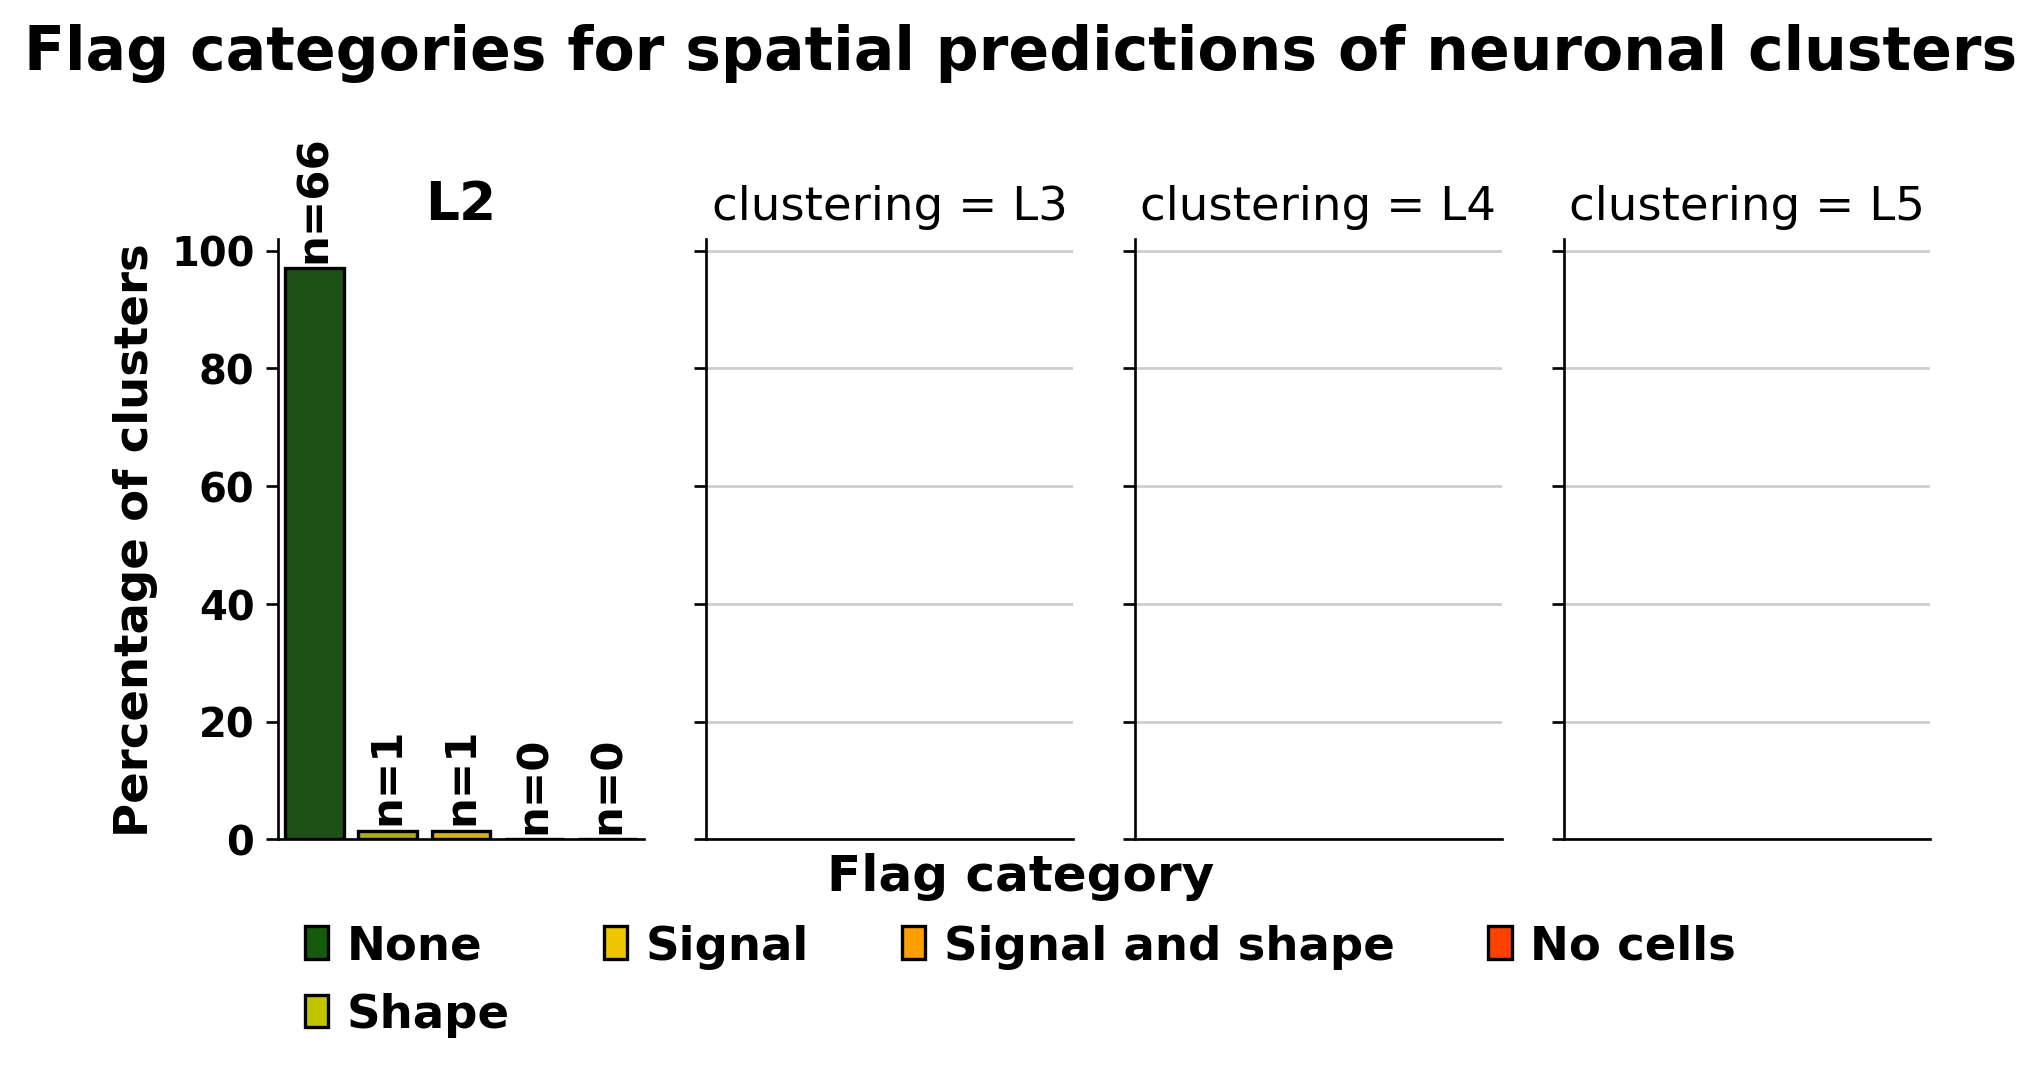

In [ ]:

# --- SETTINGS ---
# Define warning order and color mapping
warning_order = ["None", "Shape", "Signal", "Signal and shape", "No cells",]
warning_colors = {
    "None": "#155b0c",
    "Shape": "#C3C400",
    "Signal": "#EFC400",
    "Signal and shape": "#FF9E00",
    "No cells": "#FF4100",
}

# --- DATA PREP ---
# Filter for is_NN == False and desired clustering levels
filtered = joined[
    (neuron_mask) &
    (joined['clustering'].isin(["L2", "L3", "L4", "L5"]))
].copy()

# Ensure 'warning' is a categorical column with defined order
filtered['warning'] = pd.Categorical(filtered['warning'], categories=warning_order, ordered=True)

# Compute count and percentage per clustering and warning
percentage_df = (
    filtered.groupby(['clustering', 'warning'])
    .size()
    .reset_index(name='count')
)

# Compute total rows per clustering group for percentage calculation
totals = percentage_df.groupby('clustering')['count'].transform('sum')
percentage_df['percentage'] = (percentage_df['count'] / totals) * 100

# --- PLOTTING ---
# Create a FacetGrid for the 4 clustering levels
g = sns.FacetGrid(
    data=percentage_df,
    col='clustering',
    col_order=['L2', 'L3', 'L4', 'L5'],
    sharey=True,
    height=5,
    aspect=0.4
)

# Plot the bar plots
g.map_dataframe(
    sns.barplot,
    x='warning',
    y='percentage',
    order=warning_order,
    palette=warning_colors,
    edgecolor='black'
)

# Annotate and style each subplot
for ax, (clustering_level, group_df) in zip(g.axes.flat, percentage_df.groupby('clustering')):
    # Add count annotations
    for warning in warning_order:
        row = group_df[group_df['warning'] == warning]
        if not row.empty:
            y_val = row['percentage'].values[0]
            count = int(row['count'].values[0])
            ax.text(
                x=warning_order.index(warning),
                y=y_val + 1,
                s=f"n={count}",
                ha='center',
                va='bottom',
                fontsize=13,
                fontweight='bold',
                rotation=90
            )

    # Clean up x-axis and y-axis
    ax.set_xlabel('')
    ax.set_xticks([])
    ax.set_ylabel('Percentage of clusters', fontsize=14, fontweight='bold')
    ax.tick_params(axis='y', labelsize=12)
    ax.set_title(f"{clustering_level}", fontsize=16, fontweight='bold')
    ax.yaxis.grid(False)

    for label in ax.get_yticklabels():
        label.set_fontweight('bold')

    sns.despine(ax=ax)

# Remove x-axis label globally
g.set_axis_labels("", "Percentage of clusters")

# --- SUPER TITLE ---
g.fig.suptitle(
    "Flag categories for spatial predictions of neuronal clusters",
    fontsize=18,
    fontweight='bold'
)

# Adjust layout to make room for legend and title
plt.tight_layout()
plt.subplots_adjust(top=0.8, bottom=0.3)

# --- LEGEND ---
# Create custom legend handles
legend_elements = [
    Patch(facecolor=warning_colors[label], edgecolor='black', label=label)
    for label in warning_order
]

# Add legend to the figure (centered below all subplots)
legend = g.fig.legend(
    handles=legend_elements,
    loc='lower center',
    ncol=4,
    frameon=False,
    title='Flag category',
    fontsize=14,
    title_fontsize=15,
    bbox_to_anchor=(0.5, 0.1)
)

# Make legend title and text bold
for text in legend.get_texts():
    text.set_fontweight('bold')
legend.get_title().set_fontweight('bold')

# --- OPTIONAL: Save to file ---
g.fig.savefig(OUTDIR / "warning_categories_by_clustering_N.pdf", dpi=300, bbox_inches='tight')

# Show the plot
plt.show()


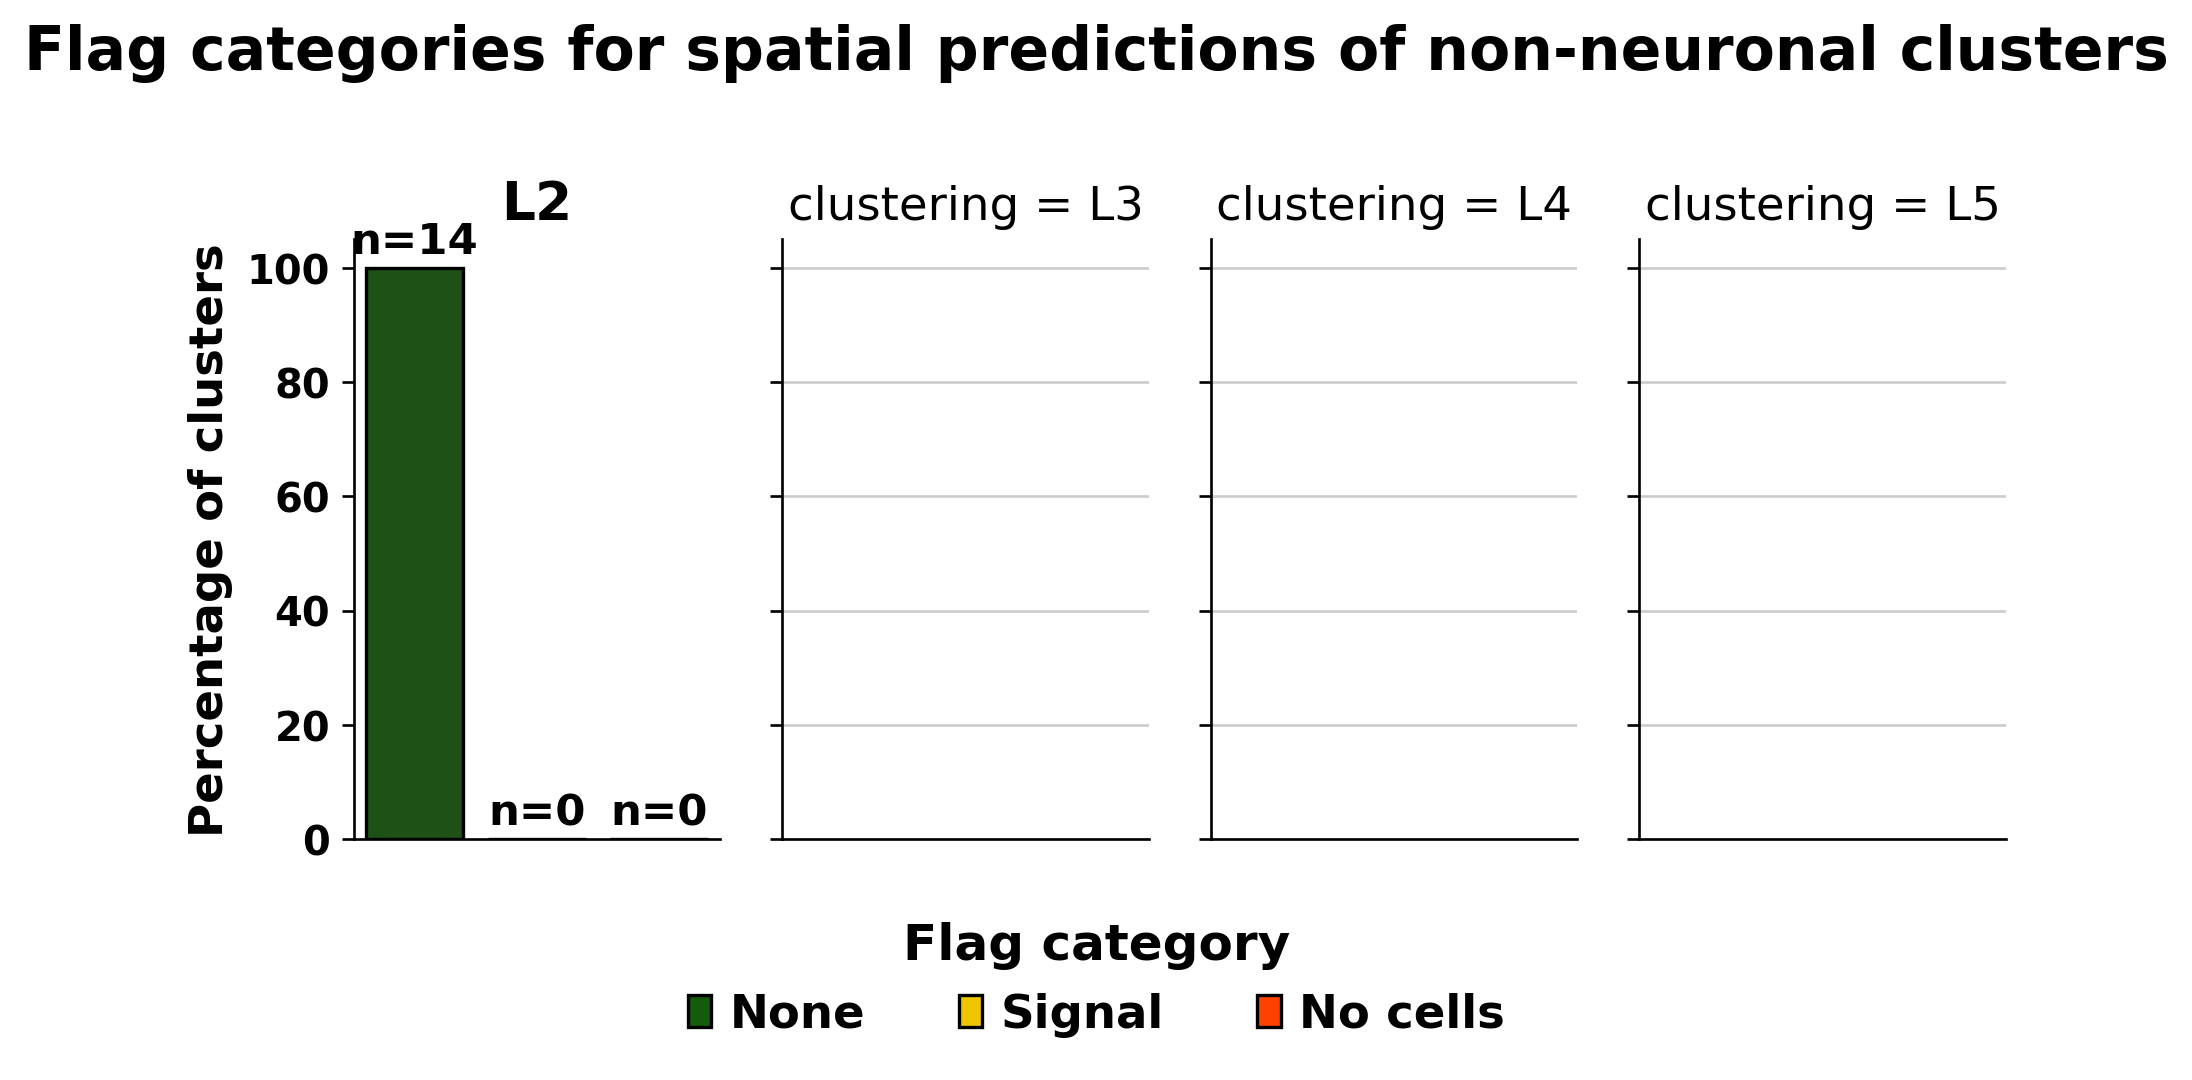

In [ ]:

# --- SETTINGS ---
# Define warning order and color mapping
warning_order = ["None", #"Shape",
"Signal", "No cells",
]
warning_colors = {
    "None": "#155b0c",
    "Shape": "#C3C400",
    "Signal": "#EFC400",
    "Signal and shape": "#FF9E00",
    "No cells": "#FF4100",
}

# --- DATA PREP ---
# Filter for is_NN == False and desired clustering levels
filtered = joined[
    (~neuron_mask) &
    (joined['clustering'].isin(["L2", "L3", "L4", "L5"]))
].copy()

# Ensure 'warning' is a categorical column with defined order
filtered['warning'] = pd.Categorical(filtered['warning'], categories=warning_order, ordered=True)

# Compute count and percentage per clustering and warning
percentage_df = (
    filtered.groupby(['clustering', 'warning'])
    .size()
    .reset_index(name='count')
)

# Compute total rows per clustering group for percentage calculation
totals = percentage_df.groupby('clustering')['count'].transform('sum')
percentage_df['percentage'] = (percentage_df['count'] / totals) * 100

# --- PLOTTING ---
# Create a FacetGrid for the 4 clustering levels
g = sns.FacetGrid(
    data=percentage_df,
    col='clustering',
    col_order=['L2', 'L3', 'L4', 'L5'],
    sharey=True,
    height=5,
    aspect=0.4
)

# Plot the bar plots
g.map_dataframe(
    sns.barplot,
    x='warning',
    y='percentage',
    order=warning_order,
    palette=warning_colors,
    edgecolor='black'
)

# Annotate and style each subplot
for ax, (clustering_level, group_df) in zip(g.axes.flat, percentage_df.groupby('clustering')):
    # Add count annotations
    for warning in warning_order:
        row = group_df[group_df['warning'] == warning]
        if not row.empty:
            y_val = row['percentage'].values[0]
            count = int(row['count'].values[0])
            ax.text(
                x=warning_order.index(warning),
                y=y_val + 1,
                s=f"n={count}",
                ha='center',
                va='bottom',
                fontsize=13,
                fontweight='bold',
                #rotation=90
            )

    # Clean up x-axis and y-axis
    ax.set_xlabel('')
    ax.set_xticks([])
    ax.set_ylabel('Percentage of clusters', fontsize=14, fontweight='bold')
    ax.tick_params(axis='y', labelsize=12)
    ax.set_title(f"{clustering_level}", fontsize=16, fontweight='bold')
    ax.yaxis.grid(False)

    for label in ax.get_yticklabels():
        label.set_fontweight('bold')

    sns.despine(ax=ax)

# Remove x-axis label globally
g.set_axis_labels("", "Percentage of clusters")

# --- SUPER TITLE ---
g.fig.suptitle(
    "Flag categories for spatial predictions of non-neuronal clusters",
    fontsize=18,
    fontweight='bold'
)

# Adjust layout to make room for legend and title
plt.tight_layout()
plt.subplots_adjust(top=0.8, bottom=0.3)

# --- LEGEND ---
# Create custom legend handles
legend_elements = [
    Patch(facecolor=warning_colors[label], edgecolor='black', label=label)
    for label in warning_order
]

# Add legend to the figure (centered below all subplots)
legend = g.fig.legend(
    handles=legend_elements,
    loc='lower center',
    ncol=3,
    frameon=False,
    title='Flag category',
    fontsize=14,
    title_fontsize=15,
    bbox_to_anchor=(0.5, 0.1)
)

# Make legend title and text bold
for text in legend.get_texts():
    text.set_fontweight('bold')
legend.get_title().set_fontweight('bold')

# --- OPTIONAL: Save to file ---
g.fig.savefig(OUTDIR / "warning_categories_by_clustering_NN.pdf", dpi=300, bbox_inches='tight')

# Show the plot
plt.show()
